# Phase 8 — PyTorch Autoencoder for Fraud Anomaly Detection

This notebook explains and inspects the trained Phase 8 model. It uses the same chronological train/validation/test split as earlier project phases.

**Goal:** learn a compact representation of legitimate transactions, reconstruct those transactions, then use reconstruction error as an anomaly score. Fraud labels are not used to train the autoencoder or to choose its primary threshold.

> Run from the project root (`fraudshield-ai`). The raw `data/raw/creditcard.csv` is required and is intentionally not included in the ZIP.

## 1. PyTorch fundamentals used here

- **Tensor:** a numeric array that PyTorch can move to CPU/GPU and use in automatic differentiation.
- **`nn.Module`:** a reusable neural-network component with trainable parameters.
- **Forward pass:** send a batch through encoder and decoder to reconstruct the input.
- **Loss:** mean-squared error (MSE) between input and reconstruction.
- **Backpropagation:** `loss.backward()` computes gradients of the loss with respect to model parameters.
- **Optimizer:** Adam updates the parameters using the computed gradients.
- **Epoch / batch:** an epoch processes the training sample once; batches let us train without putting the entire dataset through the model at once.
- **`model.train()` / `model.eval()`:** switch behavior for training and inference. `torch.no_grad()` disables gradient tracking when scoring.

The autoencoder sees only legitimate training transactions. It is therefore learning to reconstruct examples of the normal class, not learning a supervised Class 0-vs-1 boundary.

## 2. Architecture and feature flow

```text
Raw transaction
  └─ V1–V28 + log1p(Amount)        (Time excluded)
       └─ StandardScaler            (fit on legitimate training rows only)
            └─ Encoder: 29 → 64 → 32 → 8
                 └─ Latent representation (8 numbers)
                      └─ Decoder: 8 → 32 → 64 → 29
                           └─ Reconstruction
                                └─ Mean squared reconstruction error
                                     └─ Anomaly if score ≥ threshold
```

We intentionally omit `Time`: because validation/test are later chronological periods, `Time` will mechanically be larger than in training and could be flagged as an anomaly merely because the clock advanced. Amount uses `log1p` because its distribution is strongly right-skewed. There are 29 input features after this transformation.

For a transaction with scaled input vector \(x\) and reconstruction \(\hat{x}\), the score is:

\[
e(x) = \frac{1}{29}\sum_{j=1}^{29}(x_j - \hat{x}_j)^2
\]

Higher scores mean this model reconstructed the input less accurately. They are **not** calibrated fraud probabilities.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
REPORT = ROOT / "reports" / "autoencoder"
from src.models.autoencoder_anomaly import (
    TransactionAutoencoder,
    load_autoencoder_artifacts,
    score_transactions,
)
from src.data.splitting import chronological_train_validation_test_split

summary = json.loads((REPORT / "autoencoder_summary.json").read_text(encoding="utf-8"))
print("Project root:", ROOT)
print("Device used:", summary["device"])
print("Best epoch:", summary["best_epoch"])
print("Normal training rows used for neural weights:", summary["model_training_normal_rows"])
print("Selected threshold:", summary["anomaly_threshold"])


Project root: /mnt/data/fraudshield-ai
Device used: cpu
Best epoch: 18
Normal training rows used for neural weights: 60000
Selected threshold: 2.461463689804077


In [2]:
# Load the saved weights and preprocessing bundle, then inspect architecture.
model, preprocessor, device = load_autoencoder_artifacts(
    ROOT / "models" / "autoencoder_state.pt",
    ROOT / "models" / "autoencoder_preprocessor.joblib",
    device_name="cpu",
)
print(model)
print("Input dimension:", model.input_dim)
print("Latent dimension:", model.latent_dim)
print("Preprocessing feature names:", preprocessor["feature_columns"])


TransactionAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=29, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=8, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=29, bias=True)
  )
)
Input dimension: 29
Latent dimension: 8
Preprocessing feature names: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount_log1p']


## 3. How training works

Each minibatch follows this sequence:

1. `optimizer.zero_grad(set_to_none=True)` clears gradients from the previous batch.
2. `reconstruction = model(batch)` runs encoder and decoder.
3. `loss = MSE(reconstruction, batch)` quantifies reconstruction error.
4. `loss.backward()` calculates gradients.
5. `optimizer.step()` updates weights.

At the end of each epoch, the script measures reconstruction loss on **legitimate validation rows only** and calculates Average Precision on the full labeled validation partition. The checkpoint is selected by the highest validation Average Precision and training stops after six epochs without improvement. This is label-informed model selection; it does not apply gradients from or train the model on validation/fraud rows. The primary anomaly threshold is independently calculated from legitimate validation reconstruction errors only. The training script uses a seeded sample of up to 60,000 normal training records for a practical CPU run, while the scaler is fit on all legitimate training rows. Increase `--max-train-normal-rows` for a larger run.

In [3]:
# Check that saved inference works on actual held-out transactions.
data = pd.read_csv(ROOT / "data" / "raw" / "creditcard.csv")
splits = chronological_train_validation_test_split(data, time_column="Time")
sample = splits.test.head(5).copy()
scores = score_transactions(
    sample,
    model_path=ROOT / "models" / "autoencoder_state.pt",
    preprocessor_path=ROOT / "models" / "autoencoder_preprocessor.joblib",
    device_name="cpu",
)
display(pd.concat([sample[["Time", "Amount", "Class"]].reset_index(drop=True), scores.reset_index(drop=True)], axis=1))


,Time,Amount,Class,anomaly_score,is_anomaly,threshold
0,145249.0,14.95,0,0.479446,0,2.461464
1,145249.0,7.70,0,0.235833,0,2.461464
2,145249.0,6.99,0,0.217007,0,2.461464
3,145250.0,460.71,0,0.658996,0,2.461464
4,145250.0,68.00,0,0.197811,0,2.461464


## 4. Threshold selection

We use the 99th percentile of reconstruction errors from **legitimate validation transactions** as the primary threshold. Conceptually, this aims for about 1% false-positive rate among legitimate validation rows without consulting fraud labels. It is not guaranteed to remain at 1% on later transactions because distributions can drift.

The sensitivity table compares predeclared validation-normal quantiles. Use it to understand the precision/recall trade-off, not to select the best-looking threshold from the test labels.

In [4]:
sensitivity = pd.read_csv(REPORT / "threshold_sensitivity.csv")
display(sensitivity)


,normal_validation_quantile,threshold,validation_fpr,validation_precision,validation_recall,validation_average_precision,test_fpr,test_precision,test_recall,test_f1,test_false_positive,test_false_negative,test_average_precision
0,0.950,1.173108,0.050017,0.016586,0.842105,0.069466,0.036617,0.027998,0.800000,0.054103,2083,15,0.15692
1,0.975,1.541258,0.025008,0.029332,0.754386,0.069466,0.016718,0.059347,0.800000,0.110497,951,15,0.15692
2,0.990,2.461464,0.010017,0.068627,0.736842,0.069466,0.005907,0.136247,0.706667,0.228448,336,22,0.15692
3,0.995,3.843675,0.005009,0.106583,0.596491,0.069466,0.002883,0.192118,0.520000,0.280576,164,36,0.15692
4,0.999,13.696615,0.001002,0.017241,0.017544,0.069466,0.000492,0.176471,0.080000,0.110092,28,69,0.15692


training_loss.png


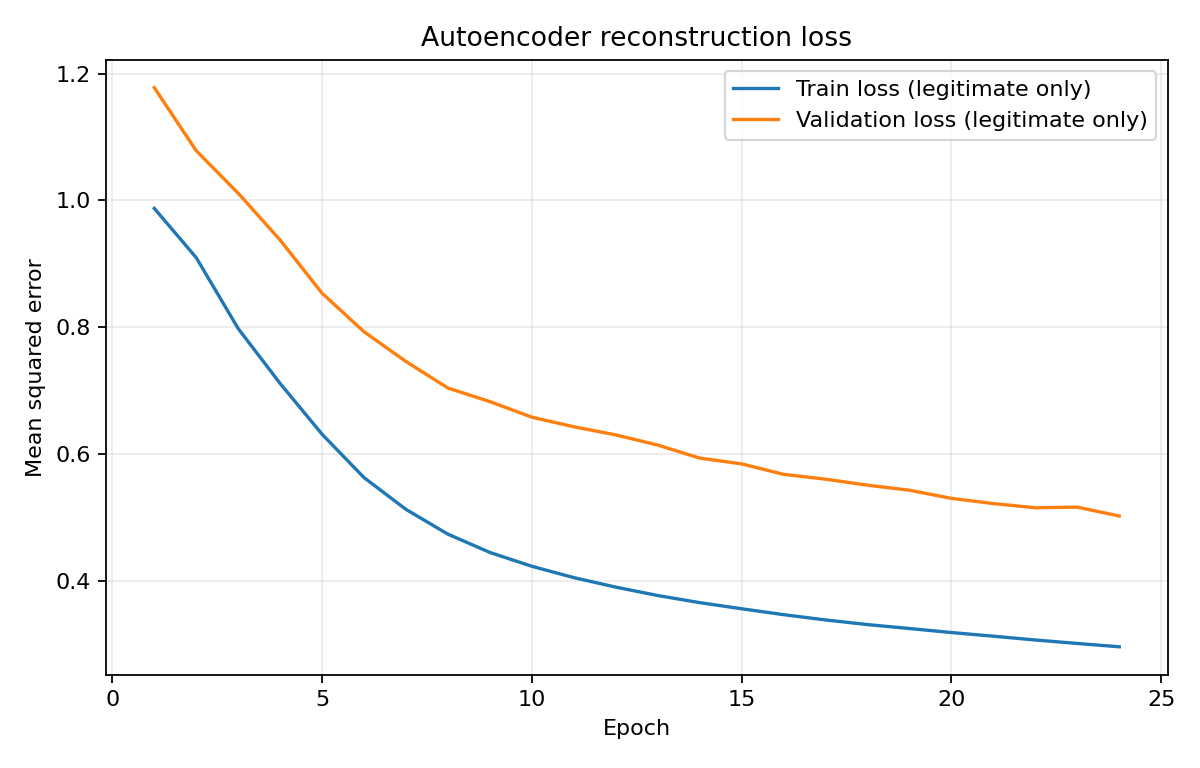

test_reconstruction_error_distribution.png


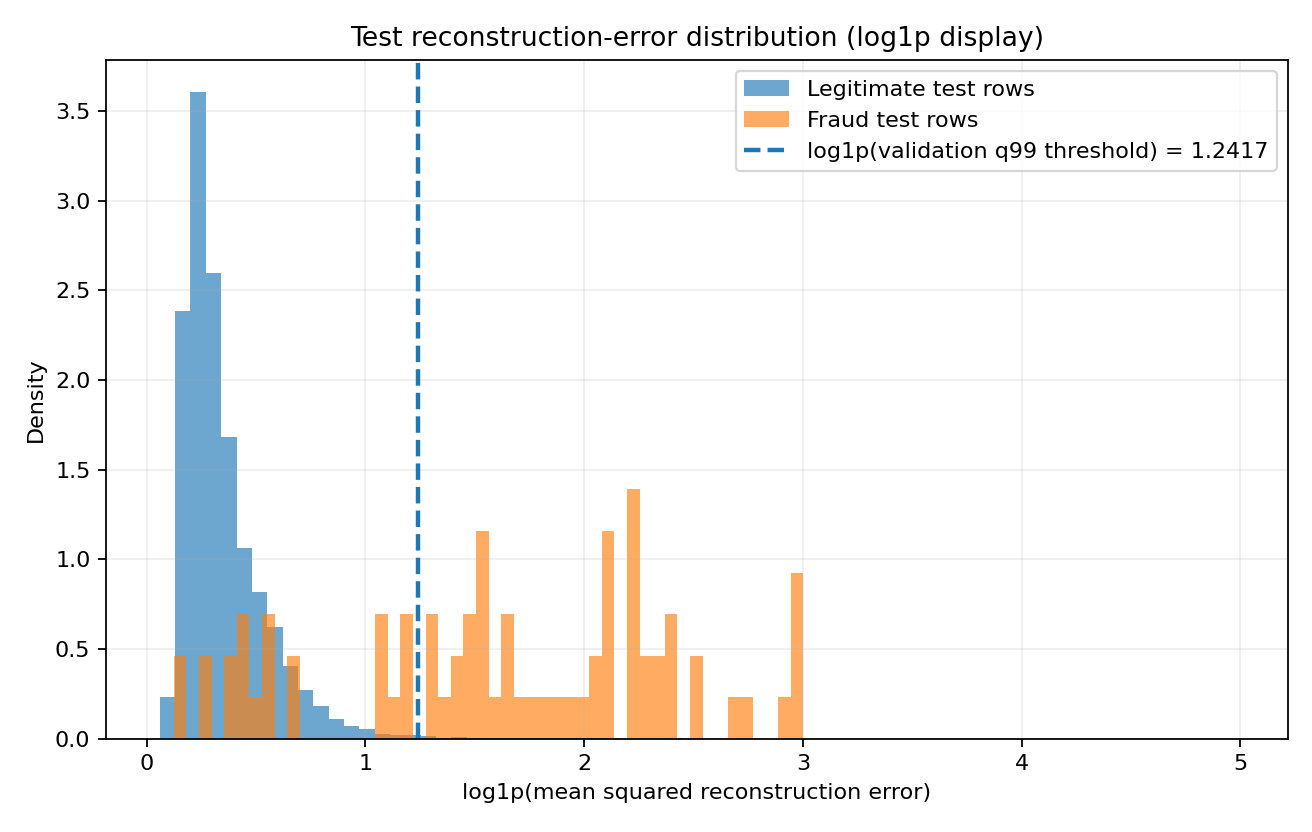

test_precision_recall_curve.png


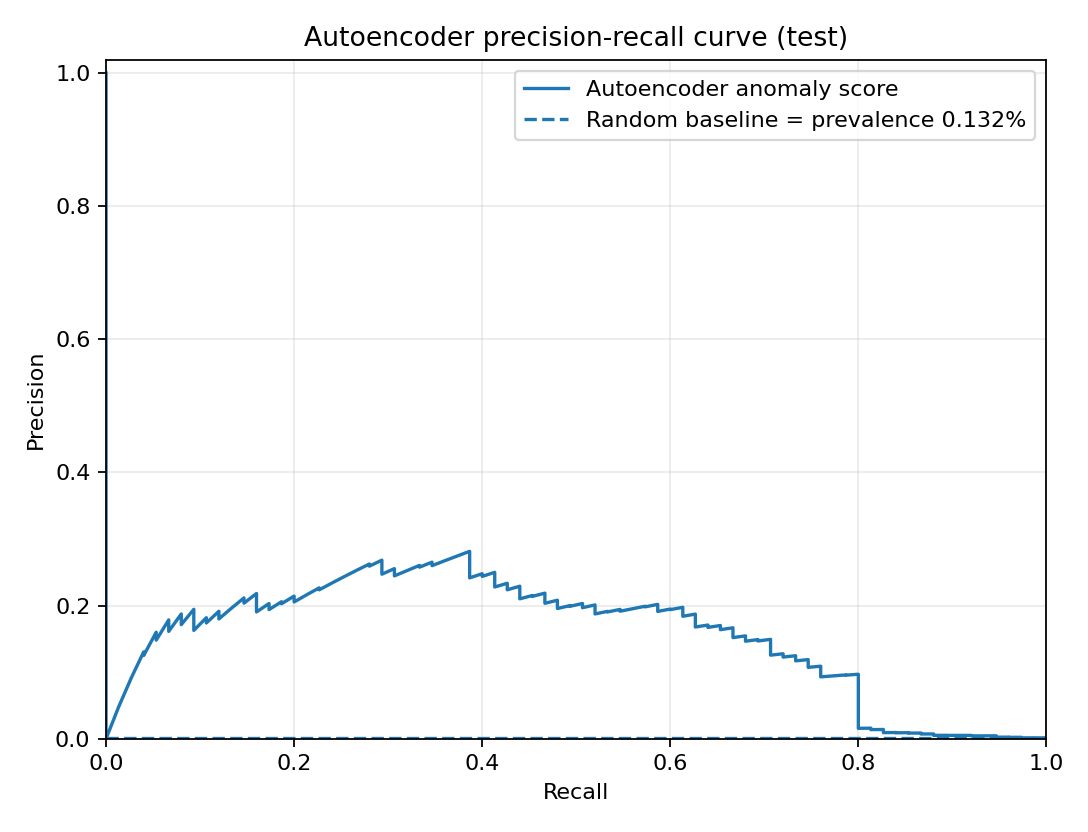

confusion_matrix_test.png


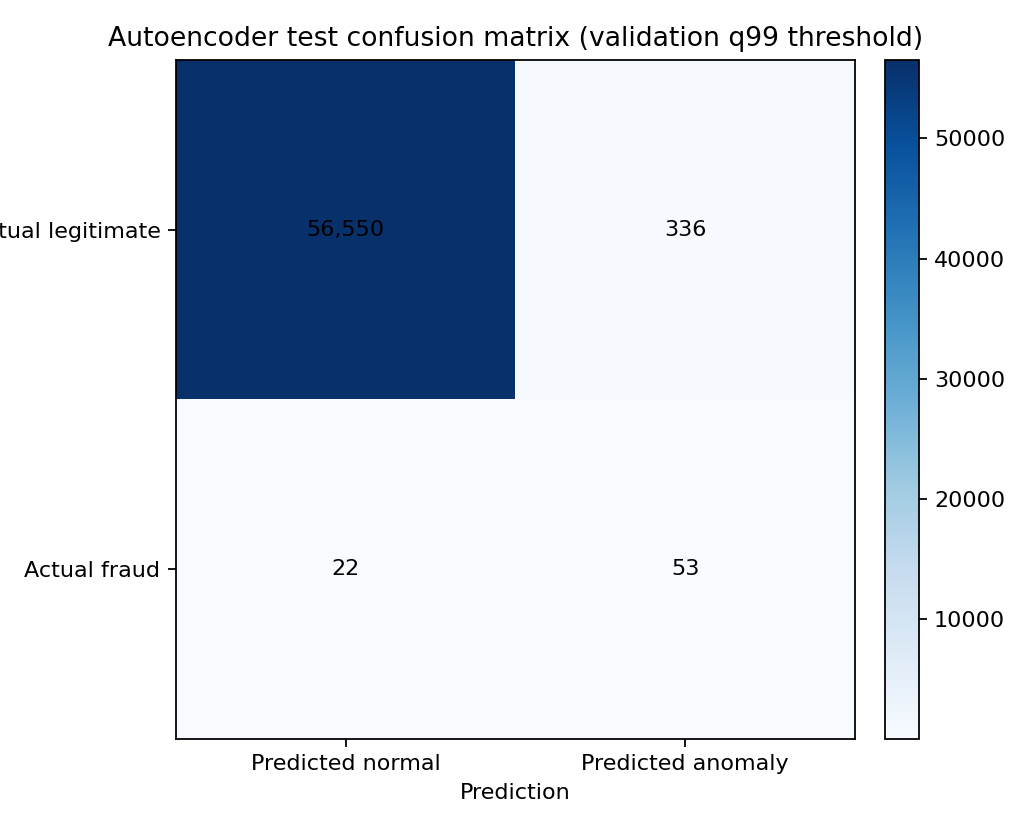

In [5]:
for image_name in [
    "training_loss.png",
    "test_reconstruction_error_distribution.png",
    "test_precision_recall_curve.png",
    "confusion_matrix_test.png",
]:
    print(image_name)
    display(Image(filename=str(REPORT / image_name)))


## 5. Actual test results and comparison with XGBoost

The autoencoder is evaluated on the same later chronological test partition as XGBoost. Average Precision evaluates ranking across thresholds; precision/recall and the confusion matrix evaluate one selected threshold. The autoencoder's threshold is a normal-validation quantile; the XGBoost threshold comes from the separate Phase 6 validation policy, so threshold-based operating points have different selection rules.

,model,threshold_method,threshold,precision,recall,f1,roc_auc,average_precision,false_positive,false_negative
0,PyTorch autoencoder (normal-only training),99.0% quantile of legitimate validation errors,2.461464,0.136247,0.706667,0.228448,0.930919,0.156920,336,22
1,XGBoost supervised baseline,Phase 6 validation-selected threshold,0.785300,0.763158,0.773333,0.768212,0.985681,0.787179,18,17


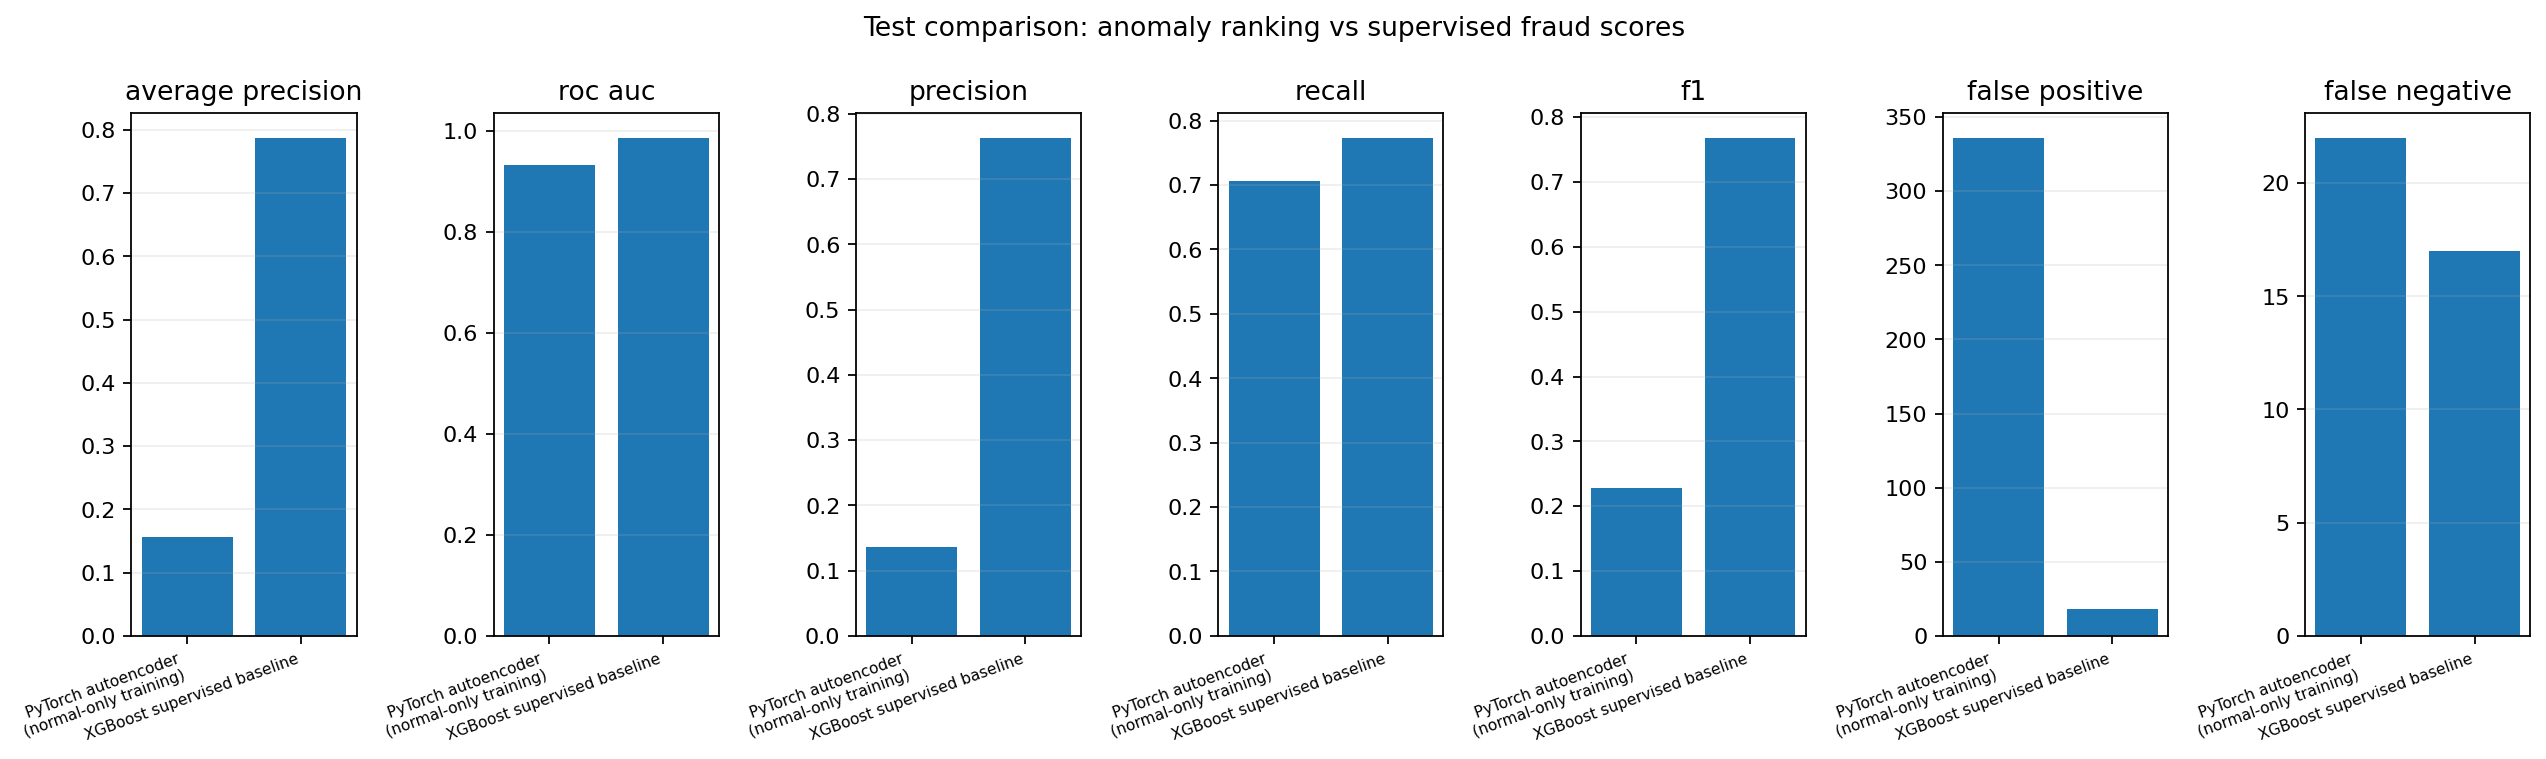

In [6]:
comparison = pd.read_csv(REPORT / "test_model_comparison.csv")
display(comparison[[
    "model", "threshold_method", "threshold", "precision", "recall", "f1",
    "roc_auc", "average_precision", "false_positive", "false_negative"
]])
display(Image(filename=str(REPORT / "test_model_comparison.png")))


## 6. Interpretation

In the final run, the autoencoder's test Average Precision is **0.1569**, compared with **0.7872** for supervised XGBoost. The autoencoder catches some fraud cases but raises many more false alerts (345 false positives at the 99th-percentile threshold) than the XGBoost Phase 6 policy (18).

The model's weights are trained only on legitimate examples, but checkpoint selection uses the labeled validation partition's Average Precision. This is label-informed model selection, not fully label-free development; it does not feed validation/fraud examples into gradient updates. Its score may still contain information about unusual patterns that XGBoost misses. Phase 9 will test complementarity on validation data before considering a hybrid. Do not claim it replaces the supervised model based on current results.

## Optional: re-run training

From PowerShell in the repository root:

```powershell
python -m pip install -r requirements.txt
python -m src.models.autoencoder_anomaly --epochs 22 --batch-size 2048 --patience 5 --max-train-normal-rows 60000 --device auto
python -m pytest -q
```

Use the official [PyTorch installer selector](https://pytorch.org/get-started/locally/) to choose a matching CPU/CUDA build on Windows. The `auto` option selects CUDA only when the installed PyTorch environment can use it.